In [1]:
import torch
import os
import monai.transforms as mt
import monai.data as md
import scipy.io as sio
import numpy as np
from liutuo_utils import compare_3d_jet,compare_3d,donkey_noise_like
import matplotlib.pyplot as plt
import pandas as pd


device_id =5
# 设置 PyTorch 的默认 CUDA 设备
torch.cuda.set_device(device_id)

# 确认当前默认 CUDA 设备
current_device = torch.cuda.current_device()
print(f"Switched to CUDA device: {current_device}")

/home/pnxc/Anaconda3/envs/xiaochou/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Switched to CUDA device: 5


In [2]:
import torch
from transformers import AutoProcessor, AutoModel
import torch.nn.functional as F

# 1. 加载 BiomedCLIP 模型和处理器
local_model_path = "/home/ssddata/liutuo/BiomedCLIP"
processor = AutoProcessor.from_pretrained(local_model_path, trust_remote_code=True)
model = AutoModel.from_pretrained(local_model_path, trust_remote_code=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
model.eval()
# 加载优化后的描述
fdg_text_optimized = (
    "FDG PET is a functional brain imaging technique that visualizes the dynamic changes in glucose metabolism, directly linked to neuronal energy demands and synaptic activity. It serves as a tool to assess functional connectivity and energy utilization across brain regions. Areas with decreased metabolic activity, such as those affected by neurodegenerative diseases, should exhibit reduced signal intensity. High-intensity metabolic hotspots in gray matter (e.g., the cerebral cortex and basal ganglia) are key markers of neuronal activity. "
    
)

av45_text_optimized = (
    "AV45 PET is a molecular imaging technique that highlights the static distribution of amyloid-beta plaques, a critical pathological marker of Alzheimer's disease. This imaging modality provides a spatial map of amyloid deposition in cortical regions (e.g., the temporal, parietal, and frontal lobes) and can distinguish amyloid-positive areas from amyloid-negative white matter regions. The primary focus is on identifying amyloid deposition patterns to assess disease progression and pathological burden."
    
)

# 提取特征向量
texts_optimized = [fdg_text_optimized, av45_text_optimized]
inputs_optimized = processor(text=texts_optimized, return_tensors="pt", padding=True).to(device)

with torch.no_grad():
    text_features_optimized = model.get_text_features(**inputs_optimized)

# 计算相似度
fdg_feature_optimized = text_features_optimized[0]
fdg_feature_optimized=fdg_feature_optimized.unsqueeze(0)
av45_feature_optimized = text_features_optimized[1]
av45_feature_optimized =av45_feature_optimized.unsqueeze(0)

cosine_similarity_optimized = F.cosine_similarity(fdg_feature_optimized, av45_feature_optimized).item()

print(f"Cosine similarity between optimized FDG PET and AV45 PET features: {cosine_similarity_optimized:.4f}")


Cosine similarity between optimized FDG PET and AV45 PET features: 0.8205


In [3]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split
import json

# 数据目录（保持不变）
base_dir = "/home/ssddata/liutuo/liutuo_data/test1"
mri_dir = "/home/ssddata/liutuo/liutuo_data/test1/MRI"
av45_dir = "/home/ssddata/liutuo/liutuo_data/test1/AV45"
fdg_dir = "/home/ssddata/liutuo/liutuo_data/test1/FDG"
csv_path = os.path.join(base_dir, "test_filtered_subjects_with_description.csv")

# JSON 文件保存路径（保持不变）
train_json_path = "/home/ssddata/liutuo/liutuo_data/test1/train_data_with_description.json"
val_json_path = "/home/ssddata/liutuo/liutuo_data/test1/val_data_with_description.json"

# 加载 CSV 文件（保持不变）
csv_data = pd.read_csv(csv_path)
csv_dict = csv_data.set_index("Subject ID")["Description"].to_dict()

# 获取文件列表（保持不变）
mri_files = sorted(os.listdir(mri_dir))
av45_files = sorted(os.listdir(av45_dir))
fdg_files = sorted(os.listdir(fdg_dir))

def get_subject_id(filename):
    """从文件名中提取统一的 subject ID（前三个部分，如 '002_S_0295'）"""
    parts = filename.split('_')
    return f"{parts[0]}_{parts[1]}_{parts[2]}"

# 使用统一的 get_subject_id 处理所有文件（保持不变）
mri_dict = {get_subject_id(f): os.path.join(mri_dir, f) for f in mri_files}
av45_dict = {get_subject_id(f): os.path.join(av45_dir, f) for f in av45_files}
fdg_dict = {get_subject_id(f): os.path.join(fdg_dir, f) for f in fdg_files}

# 匹配文件并加入描述信息和 Subject ID
paired_data = []
for patient_id, mri_file in mri_dict.items():
    if patient_id in av45_dict and patient_id in fdg_dict:
        # 检查描述信息是否存在
        description = csv_dict.get(patient_id, None)  # 从 csv_dict 中获取 Description 信息
        # 构建数据条目
        paired_data.append({
            "name": patient_id,  # 添加 name 字段
            "mri": os.path.join(mri_dir, mri_file),
            "av45": os.path.join(av45_dir, av45_dict[patient_id]),
            "fdg": os.path.join(fdg_dir, fdg_dict[patient_id]),
            "description": description  # 加入 Description 信息
        })

print(f"Total matched pairs with description: {len(paired_data)}")
# 在 paired_data 中新增键 fdg_index 和 av45_index
for idx, data in enumerate(paired_data):
    data["fdg_index"] = idx  # 将样本在 paired_data 中的索引作为 fdg_index
    data["av45_index"] = idx

import torch
from transformers import AutoTokenizer, AutoModel

# 示例：假设已经加载 BiomedCLIP 模型和处理器
# 这里替换为您实际使用的 BiomedCLIP 模型和 tokenizer
local_model_path = "/home/ssddata/liutuo/BiomedCLIP"
processor = AutoProcessor.from_pretrained(local_model_path, trust_remote_code=True)
model = AutoModel.from_pretrained(local_model_path, trust_remote_code=True)

device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
model.to(device)
model.eval()


# 假设 paired_data 已经加载
modal_information = [data["description"] for data in paired_data if data["description"] is not None]

# 对描述信息进行 Tokenizer 编码
text_inputs = processor(
    modal_information,
    padding=True,
    truncation=True,
    return_tensors="pt",
    max_length=256 # 根据模型输入限制选择合适的 max_length
).to(device)

# 转化为 BiomedCLIP 嵌入
with torch.no_grad():
    desc_text_features = model.get_text_features(text_inputs['input_ids'])  # 使用模型方法提取嵌入
    print(f"Shape of features: {desc_text_features.shape}, Dtype: {desc_text_features.dtype}")

# 划分训练集和验证集
train_data, val_data = train_test_split(paired_data, test_size=1, random_state=42)

print(f"Training set size: {len(train_data)}")
print(f"Validation set size: {len(val_data)}")

# 保存到 JSON 文件
with open(train_json_path, "w") as f:
    json.dump(train_data, f, indent=4)

with open(val_json_path, "w") as f:
    json.dump(val_data, f, indent=4)

print(f"Saved train data to: {train_json_path}")
print(f"Saved validation data to: {val_json_path}")

Total matched pairs with description: 2
Shape of features: torch.Size([2, 512]), Dtype: torch.float32
Training set size: 1
Validation set size: 1
Saved train data to: /home/ssddata/liutuo/liutuo_data/test1/train_data_with_description.json
Saved validation data to: /home/ssddata/liutuo/liutuo_data/test1/val_data_with_description.json


In [4]:
# 验证训练集
with open(train_json_path, "r") as f:
    train_data = json.load(f)
print(f"Loaded {len(train_data)} training samples.")
print("First training sample:", train_data[0])

# 验证验证集
with open(val_json_path, "r") as f:
    val_data = json.load(f)
print(f"Loaded {len(val_data)} validation samples.")
print("First validation sample:", val_data[0])



Loaded 1 training samples.
First training sample: {'name': '037_S_0552', 'mri': '/home/ssddata/liutuo/liutuo_data/test1/MRI/037_S_0552_MRI_registered.nii.gz', 'av45': '/home/ssddata/liutuo/liutuo_data/test1/AV45/037_S_0552_AV45_registered.nii.gz', 'fdg': '/home/ssddata/liutuo/liutuo_data/test1/FDG/037_S_0552_FDG_registered.nii.gz', 'description': 'Subject is a 60-year-old female with a weight of 65.4 kg. The global Clinical Dementia Rating (CDR) score, which assesses dementia severity (0: no dementia to 3: severe dementia), is 0.5. The Mini-Mental State Examination (MMSE) score, assessing cognitive function (0: severe impairment to 30: normal), is 27. The Geriatric Depression Scale (GDS) score, screening depression (0: no depression to 15: severe depression), is 0. The Functional Activities Questionnaire (FAQ) score, assessing daily activity impairment (0: no impairment to 30: severe impairment), is 7. The Neuropsychiatric Inventory Questionnaire (NPI-Q) Total Score, assessing neuropsy

In [5]:
from monai.transforms import Compose, LoadImaged, Lambdad, EnsureChannelFirstd, Orientationd, CropForegroundd, \
    HistogramNormalized, ResizeWithPadOrCropd, Spacingd, NormalizeIntensityd, ScaleIntensityd
from monai.data import CacheDataset, DataLoader
import nibabel as nib
import numpy as np
import json

import monai.transforms as mt

# 定义 transform 函数
def fdg_index_transform(x):
    return torch.cat([desc_text_features[x].unsqueeze(0), fdg_feature_optimized], dim=0)

def av45_index_transform(x):
    return torch.cat([desc_text_features[x].unsqueeze(0), av45_feature_optimized], dim=0)


# 自定义加载函数
def mat_load(filepath):
    """
    使用 nibabel 加载 NIfTI 文件，并转换为 NumPy 数组。
    """
    return nib.load(filepath).get_fdata()

# 加载 JSON 文件
train_json_path = "/home/ssddata/liutuo/liutuo_data/test1/train_data_with_description.json"
val_json_path = "/home/ssddata/liutuo/liutuo_data/test1/val_data_with_description.json"

# 加载 JSON 文件
with open(train_json_path, "r") as f:
    train_data = json.load(f)

with open(val_json_path, "r") as f:
    val_data = json.load(f)

# 转换数据格式
train_data = [
    {
        "name": item["name"],
        "mri": item["mri"],
        "av45": item["av45"],
        "fdg": item["fdg"],
        "description": item.get("description", {}),  # 确保 description 存在
        "fdg_index": item.get("fdg_index"),  # 保留 fdg_index
        "av45_index": item.get("av45_index"),  # 保留 av45_index
    }
    for item in train_data
]

val_data = [
    {
        "name": item["name"],
        "mri": item["mri"],
        "av45": item["av45"],
        "fdg": item["fdg"],
        "description": item.get("description", {}),  # 确保 description 存在
        "fdg_index": item.get("fdg_index"),  # 保留 fdg_index
        "av45_index": item.get("av45_index"),  # 保留 av45_index
    }
    for item in val_data
]



# 构建数据增强 pipeline
# 定义训练集数据增强流程
train_transforms = mt.Compose([
    mt.Lambdad(keys=["mri", "fdg","av45"], func=mat_load),  # 加载 NIfTI 文件
    mt.EnsureChannelFirstd(keys=["mri", "fdg","av45"],channel_dim='no_channel'),
    mt.Orientationd(keys=["mri", "fdg","av45"], axcodes="LPI"),
    mt.CropForegroundd(keys=["mri", "fdg","av45"], source_key="mri"),
    mt.HistogramNormalized(keys=["mri"]),
    mt.ResizeWithPadOrCropd(keys=["mri", "fdg","av45"], spatial_size=[160, 192, 160]),
    mt.Spacingd(keys=["mri", "fdg","av45"], pixdim=(1.0, 1.0, 1.0)),
    mt.NormalizeIntensityd(keys=["mri", "fdg","av45"]),
    mt.ScaleIntensityd(keys=["mri", "fdg","av45"]),
    mt.Lambdad(keys=["fdg_index"], func=fdg_index_transform),  # 添加 fdg_index 转换
    mt.Lambdad(keys=["av45_index"], func=av45_index_transform),  # 添加 av45_index 转换
])

# 定义验证集数据增强流程（通常与训练集一致，但不含随机性增强）
val_transforms = mt.Compose([
    mt.Lambdad(keys=["mri", "fdg","av45"], func=mat_load),  # 加载 NIfTI 文件
    mt.EnsureChannelFirstd(keys=["mri", "fdg","av45"],channel_dim='no_channel'),
    mt.Orientationd(keys=["mri", "fdg","av45"], axcodes="LPI"),
    mt.CropForegroundd(keys=["mri", "fdg","av45"], source_key="mri"),
    mt.HistogramNormalized(keys=["mri"]),
    mt.ResizeWithPadOrCropd(keys=["mri", "fdg","av45"], spatial_size=[160, 192, 160]),
    mt.Spacingd(keys=["mri", "fdg","av45"], pixdim=(1.0, 1.0, 1.0)),
    mt.NormalizeIntensityd(keys=["mri", "fdg","av45"]),
    mt.ScaleIntensityd(keys=["mri", "fdg","av45"]),
    mt.Lambdad(keys=["fdg_index"], func=fdg_index_transform),  # 添加 fdg_index 转换
    mt.Lambdad(keys=["av45_index"], func=av45_index_transform),  # 添加 av45_index 转换
])


# 构建 CacheDataset
train_ds = CacheDataset(data=train_data, transform=train_transforms, num_workers=0, )
train_loader = DataLoader(train_ds, batch_size=1, shuffle=True, num_workers=0)    #shuffle=True

val_ds = CacheDataset(data=val_data, transform=val_transforms, num_workers=0, )
val_loader = DataLoader(val_ds, batch_size=1, shuffle=False, num_workers=0)

# 测试 DataLoader
for batch_data in train_loader:
    print("MRI shape:", batch_data["mri"].shape)
    print("AV45 shape:", batch_data["av45"].shape)
    print("FDG shape:", batch_data["fdg"].shape)
    print("description:", train_data[0]["description"])  # 从原始数据访问描述信息
    break

/home/ssddata/liutuo/monai/utils/deprecate_utils.py:321: FutureWarning: monai.transforms.croppad.dictionary CropForegroundd.__init__:allow_smaller: Current default value of argument `allow_smaller=True` has been deprecated since version 1.2. It will be changed to `allow_smaller=False` in version 1.5.
  warn_deprecated(argname, msg, warning_category)
Loading dataset: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:01<00:00,  1.17s/it]

MRI shape: torch.Size([1, 1, 160, 192, 160])
AV45 shape: torch.Size([1, 1, 160, 192, 160])
FDG shape: torch.Size([1, 1, 160, 192, 160])
description: Subject is a 60-year-old female with a weight of 65.4 kg. The global Clinical Dementia Rating (CDR) score, which assesses dementia severity (0: no dementia to 3: severe dementia), is 0.5. The Mini-Mental State Examination (MMSE) score, assessing cognitive function (0: severe impairment to 30: normal), is 27. The Geriatric Depression Scale (GDS) score, screening depression (0: no depression to 15: severe depression), is 0. The Functional Activities Questionnaire (FAQ) score, assessing daily activity impairment (0: no impairment to 30: severe impairment), is 7. The Neuropsychiatric Inventory Questionnaire (NPI-Q) Total Score, assessing neuropsychiatric symptom burden (0: no symptoms to higher scores indicating greater burden), is 3.


Subject name: 037_S_0552


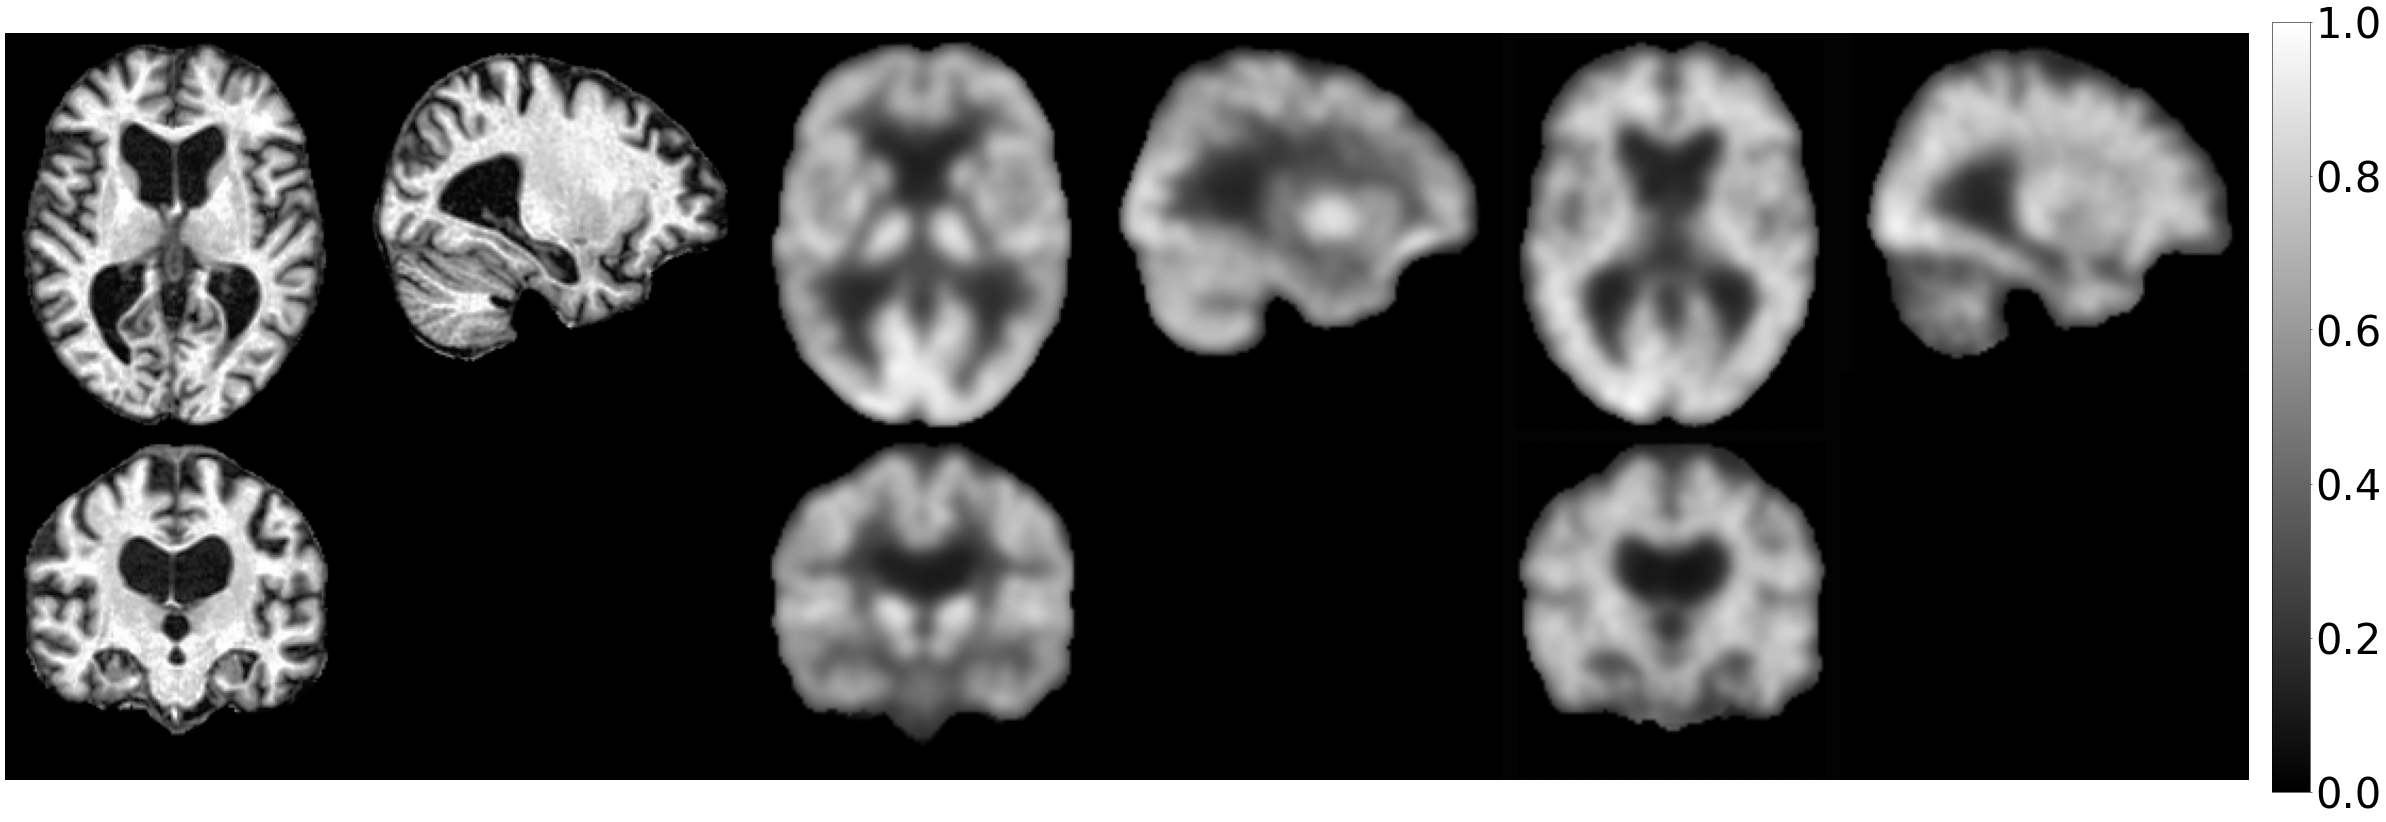

In [6]:
for batch in train_loader:
    image_mri =batch["mri"].to(device)
    seg_fdg = batch["fdg"].to(device) # this is the ground truth segmentation
    seg_av45 = batch["av45"].to(device)
    fdg_index=batch["fdg_index"].to(device)
    av45_index=batch["av45_index"].to(device)
    names = batch["name"]  # Extract subject information

   
    for idx, name in enumerate(names):
         print(f"Subject name: {name}")
    compare_3d([image_mri, seg_fdg,seg_av45])
    break  # Uncomment to compare only the first batch , label_1,label_2


In [7]:
import os
os.environ["TOKENIZERS_PARALLELISM"] = "false"
from torch.amp import GradScaler, autocast  # 从 torch.amp 导入 GradScaler

from generative.networks.nets import DiffusionModelUNet
from generative.networks.schedulers import DDPMScheduler,DDIMScheduler
from generative.inferers import DiffusionInferer
model= DiffusionModelUNet(
    spatial_dims=3,
    in_channels=1,#1,
    out_channels=1,
    num_channels=(32,64,64,128),
    attention_levels=(False,False,False,True),
    num_res_blocks=1,
    num_head_channels=(0,0,0, 128),
    with_conditioning=True,
    cross_attention_dim=512,
    use_flash_attention=True,
)



model.to(device)
scheduler = DDPMScheduler(prediction_type="v_prediction", num_train_timesteps=1000,schedule="scaled_linear_beta",
                          beta_start=0.0005, beta_end=0.0195)
scheduler.set_timesteps(num_inference_steps=1000)
optimizer= torch.optim.Adam(params=model.parameters(), lr=2.5e-5)
inferer = DiffusionInferer(scheduler)

In [18]:
import os
import torch
from monai.metrics import MAEMetric, MSEMetric, PSNRMetric
from generative.metrics import SSIMMetric
from tqdm import tqdm
import numpy as np
import nibabel as nib  # 用于保存 NIfTI 格式的图像
import monai.transforms as mt

# 加载检查点
checkpoint_path = '/home/ssddata/liutuo/checkpoint/mri2pet _two trace_add clip_flow_noHistogramNormalized/first_part_140.pth'
checkpoint = torch.load(checkpoint_path)

# 初始化模型和优化器
model.load_state_dict(checkpoint['model'])
model.eval()  # 设置为推理模式
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

# 定义评估指标
ssim_metric = SSIMMetric(spatial_dims=3, data_range=1.0, kernel_size=7)
psnr_metric = PSNRMetric(max_val=1.0)
mse_metric = MSEMetric()
mae_metric = MAEMetric()

# 推理过程
clip_sample_min = 0  # 设置合适的最小值
clip_sample_max = 1  # 设置合适的最大值

# 创建保存目录
output_dirs = {
    "mri": "/home/ssddata/liutuo/liutuo_data/test1/ddim/data_augmentation_mri",
    "fdg": "/home/ssddata/liutuo/liutuo_data/test1/ddim/data_augmentation_fdg",
    "av45": "/home/ssddata/liutuo/liutuo_data/test1/ddim/data_augmentation_av45",
    "generated_fdg": "/home/ssddata/liutuo/liutuo_data/test1/ddim/data_augmentation_fdg_generated",
    "generated_av45": "/home/ssddata/liutuo/liutuo_data/test1/ddim/data_augmentation_av45_generated"
}
for dir_path in output_dirs.values():
    os.makedirs(dir_path, exist_ok=True)

# 数据增强变换
orientation_transform = mt.Orientationd(keys=["mri", "av45", "fdg"], axcodes="LPI")

with torch.no_grad():
    for step, data_val in enumerate(tqdm(train_loader, desc="Inference")):
        # 数据增强处理
        data_val = data_val  # data_val = orientation_transform(data_val)

        images = data_val["mri"].to(device)
        seg_fdg = data_val["fdg"].to(device)  # Ground truth FDG
        seg_av45 = data_val["av45"].to(device)  # Ground truth AV45
        fdg_index = data_val["fdg_index"].to(device)
        av45_index = data_val["av45_index"].to(device)
        names = data_val["name"]
        # 检查 FDG 和 AV45 数据是否为二值化（只有 0 和 1）
        has_fdg = not torch.all((seg_fdg == 0) | (seg_fdg == 1))  # 如果不是二值化数据，则参与计算
        has_av45 = not torch.all((seg_av45 == 0) | (seg_av45 == 1))  # 如果不是二值化数据，则参与计算

        # 固定 time_embedding 和 t
        time_embedding = torch.tensor([0], device=device, dtype=torch.long)
        t = time_embedding.float() / 1000  # t = 0

        # FDG 输出（仅当非二值化时计算）
        if has_fdg:
            v_fdg_output = model(
                x=images,
                timesteps=time_embedding,
                context=fdg_index
            )
            x_fdg_t = images + (v_fdg_output)  # t = 0，因此 x_fdg_t = images
            x_fdg_t = torch.clamp(x_fdg_t, min=clip_sample_min, max=clip_sample_max)

            # 检查形状并保存生成的 FDG 图像
            if x_fdg_t.shape == (1, 1, 160, 192, 160):
                x_fdg_t = x_fdg_t.squeeze()  # 去掉前两个维度 (1, 1)，得到 [160, 192, 160]
                x_fdg_np = x_fdg_t.cpu().numpy()  # 转换为 NumPy 数组
                output_path = os.path.join(output_dirs["generated_fdg"], f'generated_fdg_{names[0]}.nii.gz')  # 保存路径
                nib.save(nib.Nifti1Image(x_fdg_np, affine=np.eye(4)), output_path)  # 保存为 NIfTI 文件
                print(f"Saved generated FDG image to {output_path}")

        # AV45 输出（仅当非二值化时计算）
        if has_av45:
            v_av45_output = model(
                x=images,
                timesteps=time_embedding,
                context=av45_index
            )
            x_av45_t = images + (v_av45_output)  # t = 0，因此 x_av45_t = images
            x_av45_t = torch.clamp(x_av45_t, min=clip_sample_min, max=clip_sample_max)

            # 检查形状并保存生成的 AV45 图像
            if x_av45_t.shape == (1, 1, 160, 192, 160):
                x_av45_t = x_av45_t.squeeze()  # 去掉前两个维度 (1, 1)，得到 [160, 192, 160]
                x_av45_np = x_av45_t.cpu().numpy()  # 转换为 NumPy 数组
                output_path = os.path.join(output_dirs["generated_av45"], f'generated_av45_{names[0]}.nii.gz')  # 保存路径
                nib.save(nib.Nifti1Image(x_av45_np, affine=np.eye(4)), output_path)  # 保存为 NIfTI 文件
                print(f"Saved generated AV45 image to {output_path}")

        # 保存真实的 MRI、FDG 和 AV45 图像
        if images.shape == (1, 1, 160, 192, 160):
            images = images.squeeze()  # 去掉前两个维度 (1, 1)，得到 [160, 192, 160]
            images_np = images.cpu().numpy()  # 转换为 NumPy 数组
            output_path = os.path.join(output_dirs["mri"], f'real_mri_{names[0]}.nii.gz')  # 保存路径
            nib.save(nib.Nifti1Image(images_np, affine=np.eye(4)), output_path)  # 保存为 NIfTI 文件
            print(f"Saved real MRI image to {output_path}")

        if seg_fdg.shape == (1, 1, 160, 192, 160):
            seg_fdg = seg_fdg.squeeze()  # 去掉前两个维度 (1, 1)，得到 [160, 192, 160]
            seg_fdg_np = seg_fdg.cpu().numpy()  # 转换为 NumPy 数组
            output_path = os.path.join(output_dirs["fdg"], f'real_fdg_{names[0]}.nii.gz')  # 保存路径
            nib.save(nib.Nifti1Image(seg_fdg_np, affine=np.eye(4)), output_path)  # 保存为 NIfTI 文件
            print(f"Saved real FDG image to {output_path}")

        if seg_av45.shape == (1, 1, 160, 192, 160):
            seg_av45 = seg_av45.squeeze()  # 去掉前两个维度 (1, 1)，得到 [160, 192, 160]
            seg_av45_np = seg_av45.cpu().numpy()  # 转换为 NumPy 数组
            output_path = os.path.join(output_dirs["av45"], f'real_av45_{names[0]}.nii.gz')  # 保存路径
            nib.save(nib.Nifti1Image(seg_av45_np, affine=np.eye(4)), output_path)  # 保存为 NIfTI 文件
            print(f"Saved real AV45 image to {output_path}")

        # 计算 SSIM、PSNR、MSE 和 MAE（仅当非二值化时计算）
        if has_fdg and x_fdg_t is not None:
            ssim_fdg_value = ssim_metric(seg_fdg.unsqueeze(0).unsqueeze(0), x_fdg_t.unsqueeze(0).unsqueeze(0))
            psnr_fdg_value = psnr_metric(seg_fdg.unsqueeze(0).unsqueeze(0), x_fdg_t.unsqueeze(0).unsqueeze(0))
            mse_fdg_value = mse_metric(seg_fdg.unsqueeze(0).unsqueeze(0), x_fdg_t.unsqueeze(0).unsqueeze(0))
            mae_fdg_value = mae_metric(seg_fdg.unsqueeze(0).unsqueeze(0), x_fdg_t.unsqueeze(0).unsqueeze(0))
            print(f"[FDG] SSIM: {ssim_fdg_value.mean().item():.4f}, "
                  f"PSNR: {psnr_fdg_value.mean().item():.4f}, "
                  f"MSE: {mse_fdg_value.mean().item():.4f}, "
                  f"MAE: {mae_fdg_value.mean().item():.4f}")

        if has_av45 and x_av45_t is not None:
            ssim_av45_value = ssim_metric(seg_av45.unsqueeze(0).unsqueeze(0), x_av45_t.unsqueeze(0).unsqueeze(0))
            psnr_av45_value = psnr_metric(seg_av45.unsqueeze(0).unsqueeze(0), x_av45_t.unsqueeze(0).unsqueeze(0))
            mse_av45_value = mse_metric(seg_av45.unsqueeze(0).unsqueeze(0), x_av45_t.unsqueeze(0).unsqueeze(0))
            mae_av45_value = mae_metric(seg_av45.unsqueeze(0).unsqueeze(0), x_av45_t.unsqueeze(0).unsqueeze(0))
            print(f"[AV45] SSIM: {ssim_av45_value.mean().item():.4f}, "
                  f"PSNR: {psnr_av45_value.mean().item():.4f}, "
                  f"MSE: {mse_av45_value.mean().item():.4f}, "
                  f"MAE: {mae_av45_value.mean().item():.4f}")

Inference:   0%|                                                                                                                                                                                                                                        | 0/1 [00:00<?, ?it/s]

Saved generated FDG image to /home/ssddata/liutuo/liutuo_data/test1/ddim/data_augmentation_fdg_generated/generated_fdg_037_S_0552.nii.gz
Saved generated AV45 image to /home/ssddata/liutuo/liutuo_data/test1/ddim/data_augmentation_av45_generated/generated_av45_037_S_0552.nii.gz
Saved real MRI image to /home/ssddata/liutuo/liutuo_data/test1/ddim/data_augmentation_mri/real_mri_037_S_0552.nii.gz
Saved real FDG image to /home/ssddata/liutuo/liutuo_data/test1/ddim/data_augmentation_fdg/real_fdg_037_S_0552.nii.gz
Saved real AV45 image to /home/ssddata/liutuo/liutuo_data/test1/ddim/data_augmentation_av45/real_av45_037_S_0552.nii.gz
[FDG] SSIM: 0.9215, PSNR: 30.5220, MSE: 0.0009, MAE: 0.0158


Inference: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.90s/it]

[AV45] SSIM: 0.8848, PSNR: 30.8085, MSE: 0.0008, MAE: 0.0163


In [19]:
import os
import numpy as np
import nibabel as nib

# 定义输入文件夹路径
input_folder = "/home/ssddata/liutuo/liutuo_data/test1/ddim/data_augmentation_av45_generated"

# 定义输出文件夹路径
output_folder = "/home/ssddata/liutuo/liutuo_data/test1/ddim/data_augmentation_av45_generated_flip"
os.makedirs(output_folder, exist_ok=True)  # 创建输出目录（如果不存在）

# 翻转函数（同时沿 x, y, z 轴翻转）
def flip_nifti_along_xyz(file_path, output_dir):
    # 加载 NIfTI 文件
    img = nib.load(file_path)
    data = img.get_fdata()  # 获取图像数据（NumPy 数组）
    affine = img.affine  # 获取仿射矩阵

    # 同时沿 x 轴、y 轴和 z 轴翻转
    flipped_xyz = np.flip(data, axis=(0, 1, 2))  # 沿 (x, y, z) 轴同时翻转
    flipped_img_xyz = nib.Nifti1Image(flipped_xyz, affine)

    # 构造输出文件名
    output_path_xyz = os.path.join(output_dir, f"{os.path.basename(file_path)}")
    nib.save(flipped_img_xyz, output_path_xyz)

    print(f"Processed: {file_path}")
    print(f"Saved flipped image to: {output_path_xyz}")

# 遍历输入文件夹中的所有文件
for filename in os.listdir(input_folder):
    if filename.endswith(".nii.gz"):  # 只处理 .nii.gz 文件
        file_path = os.path.join(input_folder, filename)
        flip_nifti_along_xyz(file_path, output_folder)

Processed: /home/ssddata/liutuo/liutuo_data/test1/ddim/data_augmentation_av45_generated/generated_av45_037_S_0552.nii.gz
Saved flipped image to: /home/ssddata/liutuo/liutuo_data/test1/ddim/data_augmentation_av45_generated_flip/generated_av45_037_S_0552.nii.gz


In [20]:
import os
import numpy as np
import nibabel as nib

# 定义输入文件夹路径
input_folder = "/home/ssddata/liutuo/liutuo_data/test1/ddim/data_augmentation_fdg_generated"

# 定义输出文件夹路径
output_folder = "/home/ssddata/liutuo/liutuo_data/test1/ddim/data_augmentation_fdg_generated_flip"
os.makedirs(output_folder, exist_ok=True)  # 创建输出目录（如果不存在）

# 翻转函数（同时沿 x, y, z 轴翻转）
def flip_nifti_along_xyz(file_path, output_dir):
    # 加载 NIfTI 文件
    img = nib.load(file_path)
    data = img.get_fdata()  # 获取图像数据（NumPy 数组）
    affine = img.affine  # 获取仿射矩阵

    # 同时沿 x 轴、y 轴和 z 轴翻转
    flipped_xyz = np.flip(data, axis=(0, 1, 2))  # 沿 (x, y, z) 轴同时翻转
    flipped_img_xyz = nib.Nifti1Image(flipped_xyz, affine)

    # 构造输出文件名
    output_path_xyz = os.path.join(output_dir, f"{os.path.basename(file_path)}")
    nib.save(flipped_img_xyz, output_path_xyz)

    print(f"Processed: {file_path}")
    print(f"Saved flipped image to: {output_path_xyz}")

# 遍历输入文件夹中的所有文件
for filename in os.listdir(input_folder):
    if filename.endswith(".nii.gz"):  # 只处理 .nii.gz 文件
        file_path = os.path.join(input_folder, filename)
        flip_nifti_along_xyz(file_path, output_folder)

Processed: /home/ssddata/liutuo/liutuo_data/test1/ddim/data_augmentation_fdg_generated/generated_fdg_037_S_0552.nii.gz
Saved flipped image to: /home/ssddata/liutuo/liutuo_data/test1/ddim/data_augmentation_fdg_generated_flip/generated_fdg_037_S_0552.nii.gz
